# ML-2: Pretrained sentence embeddings

In ML-1 the model only knew **exact words**. "Fix my bike" shares no words with "Bicycle repair and tune up", so a word-counting model can miss that they mean the same thing.

A **pretrained sentence model** was trained by someone else on huge amounts of text, and has learned what words and sentences *mean*. It turns any text into a list of numbers, called an **embedding**. Texts with similar meaning get similar numbers.

We will use `all-MiniLM-L6-v2`: free, open source (Apache 2.0 licence), about 90 MB, and fast on an ordinary laptop. **The first run downloads it, so you need an internet connection.** No account is needed.

In this notebook you will:

1. See that embeddings capture meaning.
2. Compare three ways to pick a category, using the same test listings as ML-1.
3. Try wording the model has never seen.
4. Use embeddings to find similar listings, which is the idea behind smarter search.

In [1]:
import sys
print(sys.executable)

c:\Users\HP\Desktop\KS Barter Hub\ml\.venv\Scripts\python.exe


In [2]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sentence_transformers import SentenceTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.pipeline import make_pipeline

c:\Users\HP\Desktop\KS Barter Hub\ml\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
encoder = SentenceTransformer("all-MiniLM-L6-v2")
print("Each text becomes", encoder.get_sentence_embedding_dimension(), "numbers")

c:\Users\HP\Desktop\KS Barter Hub\ml\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\HP\.cache\huggingface\hub\models--sentence-transformers--all-MiniLM-L6-v2. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
c:\Users\HP\Desktop\KS Barter Hub\ml\.venv\Lib\site-packages\huggingface_hub\file_download

Each text becomes 384 numbers


C:\Users\HP\AppData\Local\Temp\ipykernel_31612\791111679.py:2: FutureWarning: The `get_sentence_embedding_dimension` method has been renamed to `get_embedding_dimension`.
  print("Each text becomes", encoder.get_sentence_embedding_dimension(), "numbers")


## 1. Meaning as numbers

Below, five sentences become five embeddings. We compare every pair with **cosine similarity**: 1 means very similar meaning, and values near 0 mean unrelated.

Look at sentences 0 and 1. They share **no words**, yet their score should be high.

In [4]:
sentences = [
    "fix my bike",
    "Bicycle repair and tune up",
    "Guitar lessons for beginners",
    "Used laptop with charger",
    "I need someone to teach me the guitar",
]
vectors = encoder.encode(sentences, normalize_embeddings=True)

labels = [f"{i}: {s}" for i, s in enumerate(sentences)]
pd.DataFrame(vectors @ vectors.T, index=labels, columns=range(len(sentences))).round(2)

,0,1,2,3,4
0: fix my bike,1.00,0.63,0.13,0.03,0.23
1: Bicycle repair and tune up,0.63,1.00,0.17,-0.06,0.15
2: Guitar lessons for beginners,0.13,0.17,1.00,0.04,0.71
3: Used laptop with charger,0.03,-0.06,0.04,1.00,0.07
4: I need someone to teach me the guitar,0.23,0.15,0.71,0.07,1.00


Because we asked for `normalize_embeddings=True`, every embedding has length 1, so the dot product (`@`) *is* the cosine similarity.

Which pairs scored highest? Does that match your own sense of which sentences mean the same thing?

## 2. Prepare the data

We load the same listings as ML-1, and turn every listing into an embedding **once**.

In [5]:
data = pd.read_csv("../data/listings.csv")
texts = (data["title"] + ". " + data["description"]).tolist()
y = data["category"].to_numpy()

start = time.time()
embeddings = encoder.encode(texts, normalize_embeddings=True, show_progress_bar=False)
print(f"Embedded {len(texts)} listings in {time.time() - start:.1f} seconds. Shape: {embeddings.shape}")

Embedded 160 listings in 0.5 seconds. Shape: (160, 384)


We use the **same split** as ML-1 (same `random_state` and `stratify`), so the results are fairly comparable. We split row numbers, so we can use them for both texts and embeddings.

In [6]:
train_idx, test_idx = train_test_split(
    np.arange(len(data)), test_size=0.25, stratify=y, random_state=42
)
print(len(train_idx), "to learn from,", len(test_idx), "to test on")

120 to learn from, 40 to test on


## 3. Three ways to choose a category

**Approach 1: TF-IDF** (from ML-1). Counts words. This is our baseline.

In [7]:
def make_tfidf_model():
    return make_pipeline(
        TfidfVectorizer(lowercase=True, ngram_range=(1, 2), stop_words="english"),
        LogisticRegression(max_iter=1000),
    )

tfidf_model = make_tfidf_model()
tfidf_model.fit([texts[i] for i in train_idx], y[train_idx])
tfidf_pred = tfidf_model.predict([texts[i] for i in test_idx])
tfidf_acc = accuracy_score(y[test_idx], tfidf_pred)
print("TF-IDF accuracy:", round(tfidf_acc, 3))

TF-IDF accuracy: 0.325


**Approach 2: zero-shot.** No training at all. We write one short description per category, turn each into an embedding, and give each listing the category whose description is **closest in meaning**.

The model never sees our labels, yet it can still guess, because it understands the words in the descriptions.

In [8]:
category_descriptions = {
    "books-and-study": "books, textbooks, notes and study material",
    "electronics": "electronics such as phones, laptops, cameras and headphones",
    "home-and-furniture": "furniture, appliances and things for the home",
    "clothing-and-accessories": "clothes, shoes, bags and accessories",
    "sports-and-outdoors": "sports equipment, bicycles, fitness and camping gear",
    "music-and-hobbies": "musical instruments, games, art supplies and hobbies",
    "kids-and-baby": "toys, clothes and gear for babies and children",
    "other-things": "other household items, collectibles and miscellaneous things",
    "tutoring-and-lessons": "teaching, tutoring, lessons and coaching",
    "repairs-and-fixing": "repairing and fixing things, such as bikes, phones and plumbing",
    "cooking-and-food": "cooking, baking, catering and food preparation",
    "design-and-creative": "design, photography, video, illustration and creative work",
    "tech-and-web": "websites, software, computers and technical help",
    "home-help": "cleaning, moving, gardening and household help",
    "care-and-wellness": "caring for people and pets, fitness, yoga and wellbeing",
    "other-services": "other services and help that do not fit elsewhere",
}
slugs = np.array(list(category_descriptions))
category_embeddings = encoder.encode(
    list(category_descriptions.values()), normalize_embeddings=True
)

zero_shot_scores = embeddings[test_idx] @ category_embeddings.T
zero_shot_pred = slugs[zero_shot_scores.argmax(axis=1)]
zero_acc = accuracy_score(y[test_idx], zero_shot_pred)
print("Zero-shot accuracy:", round(zero_acc, 3))

Zero-shot accuracy: 0.65


**Approach 3: embeddings plus a trained classifier.** We keep the pretrained model's understanding, and train only a small logistic regression on top, using our labelled examples. This is the first taste of **transfer learning**: reuse what a big model already knows, and teach it only the small last step.

In [9]:
emb_clf = LogisticRegression(max_iter=2000)
emb_clf.fit(embeddings[train_idx], y[train_idx])
emb_acc = accuracy_score(y[test_idx], emb_clf.predict(embeddings[test_idx]))
print("Embeddings + classifier accuracy:", round(emb_acc, 3))

Embeddings + classifier accuracy: 0.65


## 4. Compare them

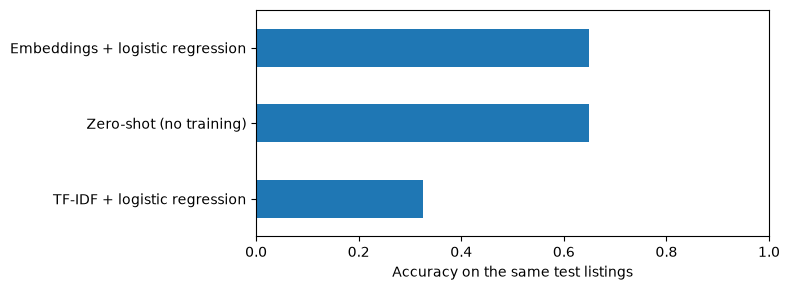

In [10]:
results = pd.Series(
    {
        "TF-IDF + logistic regression": tfidf_acc,
        "Zero-shot (no training)": zero_acc,
        "Embeddings + logistic regression": emb_acc,
    }
).sort_values()

results.plot.barh(figsize=(8, 3), xlim=(0, 1))
plt.xlabel("Accuracy on the same test listings")
plt.tight_layout()
plt.show()

One split can mislead, especially with so few listings. As in ML-1, we repeat the test five times with different splits and average. (Zero-shot has no training, so we simply score it on all listings.)

In [11]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

tfidf_cv = cross_val_score(make_tfidf_model(), texts, y, cv=cv).mean()
emb_cv = cross_val_score(LogisticRegression(max_iter=2000), embeddings, y, cv=cv).mean()
zero_all = accuracy_score(y, slugs[(embeddings @ category_embeddings.T).argmax(axis=1)])

print("Average accuracy over 5 rounds")
print("  TF-IDF:      ", round(tfidf_cv, 3))
print("  Zero-shot:   ", round(zero_all, 3))
print("  Embeddings:  ", round(emb_cv, 3))

Average accuracy over 5 rounds
  TF-IDF:       0.3
  Zero-shot:    0.7
  Embeddings:   0.706


## 5. Wording the model has never seen

This is where embeddings should help most. The listings below use words that do **not** appear in our dataset.

In [12]:
def compare(title, description=""):
    text = f"{title}. {description}".strip()
    tfidf_probs = tfidf_model.predict_proba([text])[0]
    emb_probs = emb_clf.predict_proba(encoder.encode([text], normalize_embeddings=True))[0]
    t, e = tfidf_probs.argmax(), emb_probs.argmax()
    print(repr(text))
    print(f"   TF-IDF     -> {tfidf_model.classes_[t]:26} {tfidf_probs[t]:.0%}")
    print(f"   Embeddings -> {emb_clf.classes_[e]:26} {emb_probs[e]:.0%}")
    print()

compare("Someone to repair my cycle")
compare("I can teach you to play the sitar")
compare("Second hand notebook computer")
compare("Help carrying boxes when I move house")
compare("asdf qwerty")

'Someone to repair my cycle.'
   TF-IDF     -> repairs-and-fixing         14%
   Embeddings -> repairs-and-fixing         17%

'I can teach you to play the sitar.'
   TF-IDF     -> care-and-wellness          7%
   Embeddings -> tutoring-and-lessons       14%

'Second hand notebook computer.'
   TF-IDF     -> tech-and-web               7%
   Embeddings -> electronics                22%

'Help carrying boxes when I move house.'
   TF-IDF     -> other-things               10%
   Embeddings -> other-things               13%

'asdf qwerty.'
   TF-IDF     -> care-and-wellness          7%
   Embeddings -> music-and-hobbies          8%



Look at the last one. Nonsense text still gets a category, and the model does not know it is nonsense. That is why we always show the **confidence**, and why the product will only show a suggestion when the model is confident enough.

## 6. Finding similar listings

The same embeddings can find listings that mean something similar to a search. This is the idea behind smarter search and matching: "someone near you has what you want".

In [13]:
def find_similar(query, top=3):
    query_vector = encoder.encode([query], normalize_embeddings=True)[0]
    scores = embeddings @ query_vector
    for i in np.argsort(-scores)[:top]:
        print(f"{scores[i]:.2f}  {data.loc[i, 'title']}  ({data.loc[i, 'category']})")

find_similar("fix my bicycle")
print()
find_similar("I want to learn an instrument")
print()
find_similar("somewhere to sit and read")

0.68  Bicycle repair and tune up  (repairs-and-fixing)
0.55  Mountain bicycle  (sports-and-outdoors)
0.44  Kids bicycle  (kids-and-baby)

0.54  Ukulele  (music-and-hobbies)
0.53  Guitar lessons for beginners  (tutoring-and-lessons)
0.45  Classical singing lessons  (tutoring-and-lessons)

0.44  Pet sitting  (care-and-wellness)
0.40  Elderly companion visits  (care-and-wellness)
0.37  Driving lessons  (other-services)


## 7. A suggestion with a confidence check

A first version of what the product will do: show the best categories, and only suggest one if the model is sure enough.

In [14]:
def suggest(title, description="", threshold=0.3, top=3):
    text = f"{title}. {description}".strip()
    probs = emb_clf.predict_proba(encoder.encode([text], normalize_embeddings=True))[0]
    ranked = sorted(zip(emb_clf.classes_, probs), key=lambda pair: pair[1], reverse=True)[:top]
    for category, prob in ranked:
        print(f"   {category:28} {prob:.0%}")
    best_category, best_prob = ranked[0]
    if best_prob >= threshold:
        print(f"-> suggest: {best_category}")
    else:
        print("-> too unsure, show no suggestion")

suggest("Used tabla set", "Good sound, comes with a cushion")
print()
suggest("Math homework help for class 9")
print()
suggest("Garden hose")

   music-and-hobbies            13%
   sports-and-outdoors          11%
   other-things                 9%
-> too unsure, show no suggestion

   tech-and-web                 9%
   other-things                 8%
   sports-and-outdoors          7%
-> too unsure, show no suggestion

   repairs-and-fixing           10%
   other-things                 9%
   sports-and-outdoors          9%
-> too unsure, show no suggestion


With only 120 training examples, the probabilities are low and spread out. That is normal. In ML-3 we will pick the threshold from data, by checking how often suggestions above each value are right.

## Experiments

Change one thing at a time, run the cells again, and write down what happens.

1. **Who wins?** Look at the bar chart and the cross-validation numbers. Which approach is best? Is the gap big or small? Why might embeddings help more when the training data is small?
2. **Improve zero-shot.** Rewrite the descriptions in `category_descriptions` with more example words. How much does the zero-shot accuracy change? You are using your knowledge to replace training data.
3. **Wording test.** Write five new listings in your own words and run `compare()`. Where do the two models disagree? Who is right?
4. **Which categories are hard?** Print the listings that the embedding classifier got wrong on the test set. Do you agree with the labels?
5. **Other languages (optional).** The model `paraphrase-multilingual-MiniLM-L12-v2` understands Hindi and Marathi too, but it is larger (about 470 MB). Try it with `compare()` on a Hindi title. Many Barter Hub members may write in Hindi or Marathi.
6. **Speed.** Check how long `encoder.encode` takes for one listing. Is that fast enough for a form that suggests a category as you type?

## What you learned

- **Embeddings** turn text into numbers that capture meaning, so new wording still lands near similar listings.
- **Transfer learning** reuses a pretrained model and trains only a small last step, which works well with little data.
- **Zero-shot** needs no training data at all, only good descriptions.
- A model always answers, even to nonsense, so **confidence** matters.

**Next (ML-3):** save the trained classifier, run it inside your Node server, and show a "Suggested category" hint in the post form.